# Visualization of the contraction from Schneider et al.

Import

In [1]:
#%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt

import pandas as pd
import os

import config
import constantes
import contraction
import profiles

from scipy.integrate import quad

from colossus.cosmology import cosmology

from matplotlib.lines import Line2D

/Users/baptistesevilla/Documents/Ecole/Stage Dark matter/Code/profiles.py:293: IntegrationWarning: The algorithm does not converge.  Roundoff error is detected
  in the extrapolation table.  It is assumed that the requested tolerance
  cannot be achieved, and that the returned result (if full_output = 1) is 
  the best which can be obtained.
  val, _ = quad(integrand, 0.0, np.inf, limit=constantes.ABEL_LIMIT, epsrel=epsrel, epsabs= constantes.ABEL_EPSABS)


Params for the plots

In [2]:
x_min = 1e-2
x_max = 2e1
y_min = 2e9
y_max = 6e16
fig = 8

plt.rcParams['axes.labelsize'] = 20  
plt.rcParams['xtick.labelsize'] = 18   
plt.rcParams['ytick.labelsize'] = 18

Choice of the dark matter profile

In [3]:
config.DM_PROFILE = 'NFW'

Creation of the contraction from the article Aurel Schneider and Romain Teyssier (2016)

In [4]:
rho_bcm, rho_rdm, rho_baryons, initial_components, m_baryon_f_array, r_f = contraction.contract_Schneider2015()

Plot of the contraction 

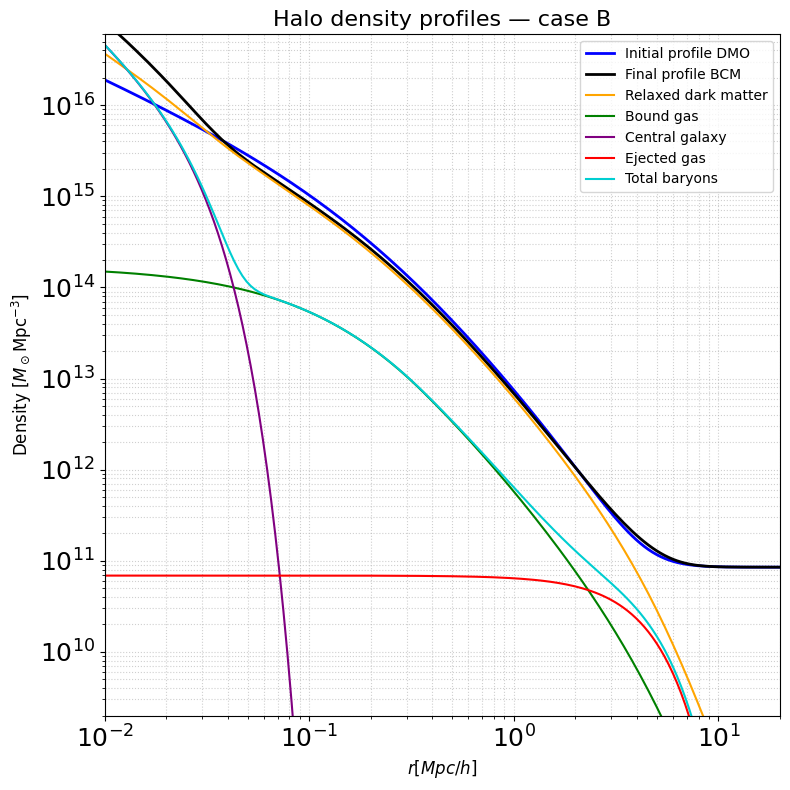

In [5]:
plt.figure(figsize=(fig,fig))
plt.loglog(config.R, initial_components["rho_i_dm"] + constantes.RHO_BG, label='Initial profile DMO', color='blue', linewidth=2)
plt.loglog(config.R, rho_bcm + constantes.RHO_BG , label='Final profile BCM', color='black', linewidth=2)
plt.loglog(config.R, constantes.F_RDM * rho_rdm, label='Relaxed dark matter', color='orange')
plt.loglog(config.R, constantes.F_BOUNDED_GAS * initial_components["rho_bounded_gas"], label='Bound gas', color='green')
plt.loglog(config.R, constantes.F_CENTRAL_GALAXY * initial_components["rho_central_galaxy"], label='Central galaxy', color='purple')
plt.loglog(config.R, constantes.F_EJECTED_GAS * initial_components["rho_ejected_gas"], label='Ejected gas', color='red')
plt.loglog(config.R, rho_baryons, label='Total baryons', color='darkturquoise')
plt.xlabel(r'$r [Mpc/h]$', fontsize=12)
plt.ylabel(r'Density [$M_\odot \mathrm{Mpc}^{-3}$]', fontsize=12)
plt.title(f'Halo density profiles — case {config.SCHNEIDER2015_CASE}', fontsize=16)
plt.legend()
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)

plt.grid(True, which='both', ls=':', alpha=0.6)
plt.tight_layout()
plt.show()

Import the data from Aurel Schneider and Romain Teyssier (2016) to compare them with mine

In [6]:
data_dir = f'../Data/Data_{config.SCHNEIDER2015_CASE}_Schneider_2015'

df_dmo = pd.read_csv(f'{data_dir}/Initial_profile_dmo.csv', sep=';', decimal=',', header=None)
df_bcm = pd.read_csv(f'{data_dir}/Final_profile_bcm.csv', sep=';', decimal=',', header=None)
df_relaxed_DM = pd.read_csv(f'{data_dir}/Relaxed_DM.csv', sep=';', decimal=',', header=None)
df_bound_gas = pd.read_csv(f'{data_dir}/Bound_gas.csv', sep=';', decimal=',', header=None)
df_central_gal = pd.read_csv(f'{data_dir}/Central_galaxy.csv', sep=';', decimal=',', header=None)
df_ejected_gas = pd.read_csv(f'{data_dir}/Ejected_gas.csv', sep=';', decimal=',', header=None)
df_background = pd.read_csv(f'{data_dir}/Background.csv', sep=';', decimal=',', header=None)
df_initial_dmo = pd.read_csv(f'{data_dir}/Initial_simulation_dmo.csv', sep=';', decimal=',', header=None)
df_final_BCM = pd.read_csv(f'{data_dir}/Final_simulation_bcm.csv', sep=';', decimal=',', header=None)

Comparison of the data from the article and mine

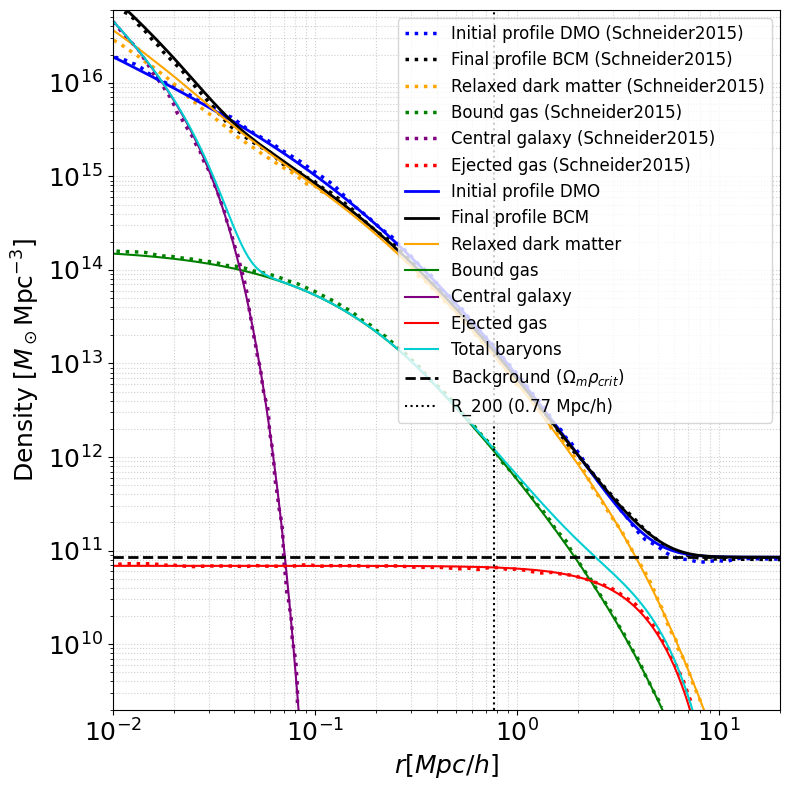

In [7]:
plt.figure(figsize=(fig,fig))
plt.loglog(df_dmo[0], df_dmo[1], label='Initial profile DMO (Schneider2015)', ls=':', lw=2.5, color='blue')
plt.loglog(df_bcm[0], df_bcm[1], label='Final profile BCM (Schneider2015)', ls=':', lw=2.5, color='black')
plt.loglog(df_relaxed_DM[0], df_relaxed_DM[1], label='Relaxed dark matter (Schneider2015)', ls=':', lw=2.5, color='orange')
plt.loglog(df_bound_gas[0], df_bound_gas[1], label='Bound gas (Schneider2015)', ls=':', lw=2.5, color='green')
plt.loglog(df_central_gal[0], df_central_gal[1], label='Central galaxy (Schneider2015)', ls=':', lw=2.5, color='purple')
plt.loglog(df_ejected_gas[0], df_ejected_gas[1], label='Ejected gas (Schneider2015)', ls=':', lw=2.5, color='red')
# plt.loglog(df_background[0], df_background[1], label='Background', ls='--', lw=2.5, color='black')
# plt.loglog(df_initial_dmo[0],df_initial_dmo[1], label='Initial simulation DMO', ls=':', lw=2.5, color='navy')
# plt.loglog(df_final_BCM[0], df_final_BCM[1], label='Final simulation BCM', ls=':', lw=2.5, color='darkcyan')

plt.loglog(config.R, initial_components["rho_i_dm"] + constantes.RHO_BG, label='Initial profile DMO', color='blue', linewidth=2)
plt.loglog(config.R, rho_bcm + constantes.RHO_BG , label='Final profile BCM', color='black', linewidth=2)
plt.loglog(config.R, constantes.F_RDM * rho_rdm, label='Relaxed dark matter', color='orange')
plt.loglog(config.R, constantes.F_BOUNDED_GAS * initial_components["rho_bounded_gas"], label='Bound gas', color='green')
plt.loglog(config.R, constantes.F_CENTRAL_GALAXY * initial_components["rho_central_galaxy"], label='Central galaxy', color='purple')
plt.loglog(config.R, constantes.F_EJECTED_GAS * initial_components["rho_ejected_gas"], label='Ejected gas', color='red')
plt.loglog(config.R, rho_baryons, label='Total baryons', color='darkturquoise')


plt.axhline(y=constantes.RHO_BG, color='black', linestyle='--', linewidth=2, label=r'Background ($\Omega_m \rho_{crit}$)')
plt.axvline(constantes.R_200, color='black', linestyle=':', label=f'R_200 ({constantes.R_200} Mpc/h)')
plt.xlabel(r'$r [Mpc/h]$', fontsize=18)
plt.ylabel(r'Density [$M_\odot \mathrm{Mpc}^{-3}$]', fontsize=18)
#plt.title(f'Comparaison with Schneider2015 & Teyssier — Case {config.SCHNEIDER2015_CASE}', fontsize=16)
plt.legend(fontsize=12)
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.grid(True, which='both', ls=':', alpha=0.6)
plt.tight_layout()
plt.show()

Visualization of the 3 cases

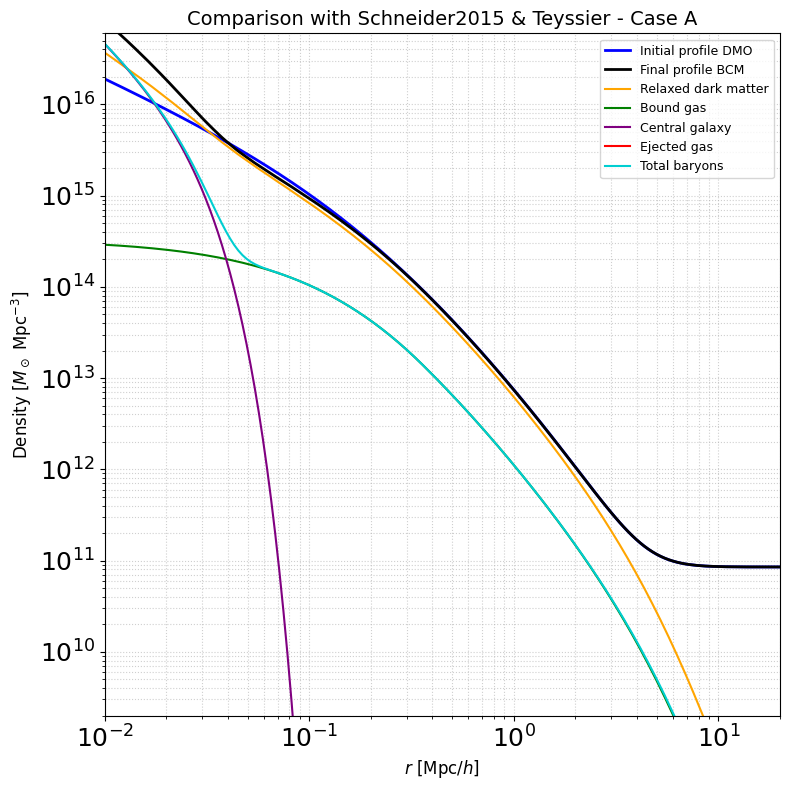

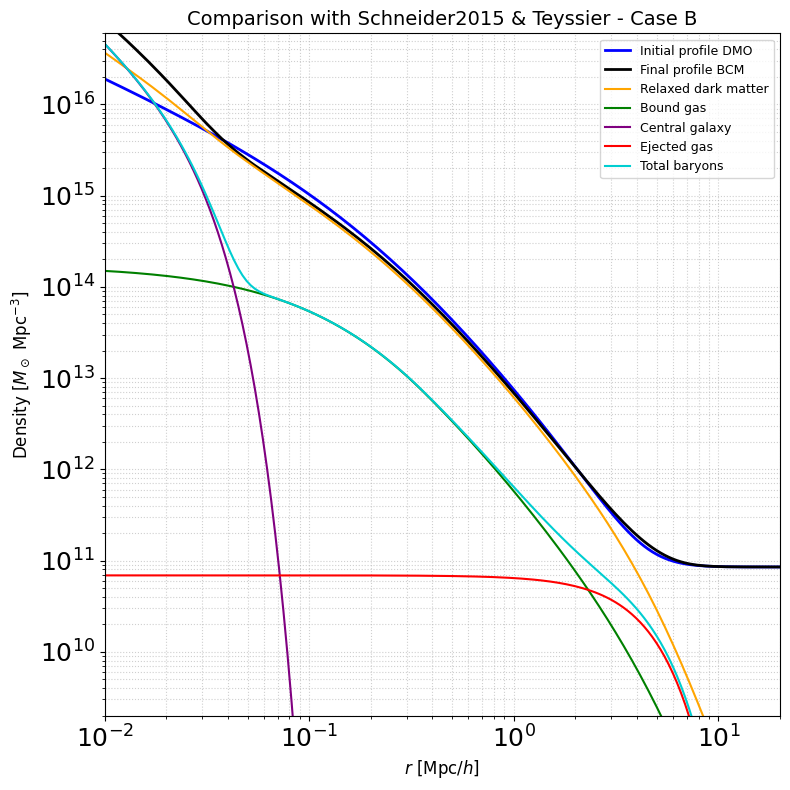

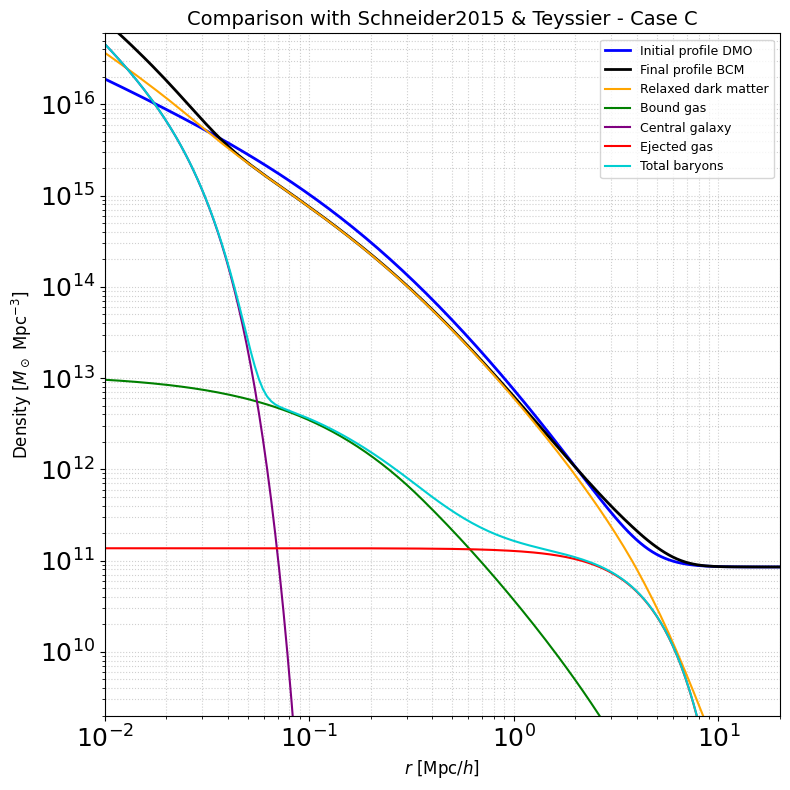

In [8]:
cases = ['A', 'B', 'C']

for case in cases:
    config.SCHNEIDER2015_CASE = case

    if case == 'A':
        constantes.F_BOUNDED_GAS = 0.151
    elif case == 'B':
        constantes.F_BOUNDED_GAS = 0.078
    elif case == 'C':
        constantes.F_BOUNDED_GAS = 0.005
        
    constantes.F_EJECTED_GAS = 1.0 - constantes.F_RDM - constantes.F_BOUNDED_GAS - constantes.F_CENTRAL_GALAXY
    
    rho_bcm, rho_rdm, rho_baryons, initial_components, m_baryon_f_array, r_f = contraction.contract_Schneider2015()
    

    plt.figure(figsize=(fig,fig))
    plt.loglog(config.R, initial_components["rho_i_dm"] + constantes.RHO_BG, label='Initial profile DMO', color='blue', linewidth=2)
    plt.loglog(config.R, rho_bcm + constantes.RHO_BG , label='Final profile BCM', color='black', linewidth=2)
    plt.loglog(config.R, constantes.F_RDM * rho_rdm, label='Relaxed dark matter', color='orange')
    plt.loglog(config.R, constantes.F_BOUNDED_GAS * initial_components["rho_bounded_gas"], label='Bound gas', color='green')
    plt.loglog(config.R, constantes.F_CENTRAL_GALAXY * initial_components["rho_central_galaxy"], label='Central galaxy', color='purple')
    plt.loglog(config.R, constantes.F_EJECTED_GAS * initial_components["rho_ejected_gas"], label='Ejected gas', color='red')
    plt.loglog(config.R, rho_baryons, label='Total baryons', color='darkturquoise')
    plt.xlabel(r'$r \ [\mathrm{Mpc}/h]$', fontsize=12)
    plt.ylabel(r'Density [$M_\odot \ \mathrm{Mpc}^{-3}$]', fontsize=12)
    plt.title(f'Comparison with Schneider2015 & Teyssier - Case {case}', fontsize=14)
    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)
    plt.grid(True, which='both', ls=':', alpha=0.6)
    plt.legend(fontsize=9, loc='upper right')
    plt.tight_layout()
    plt.show()

Stacking of the cases

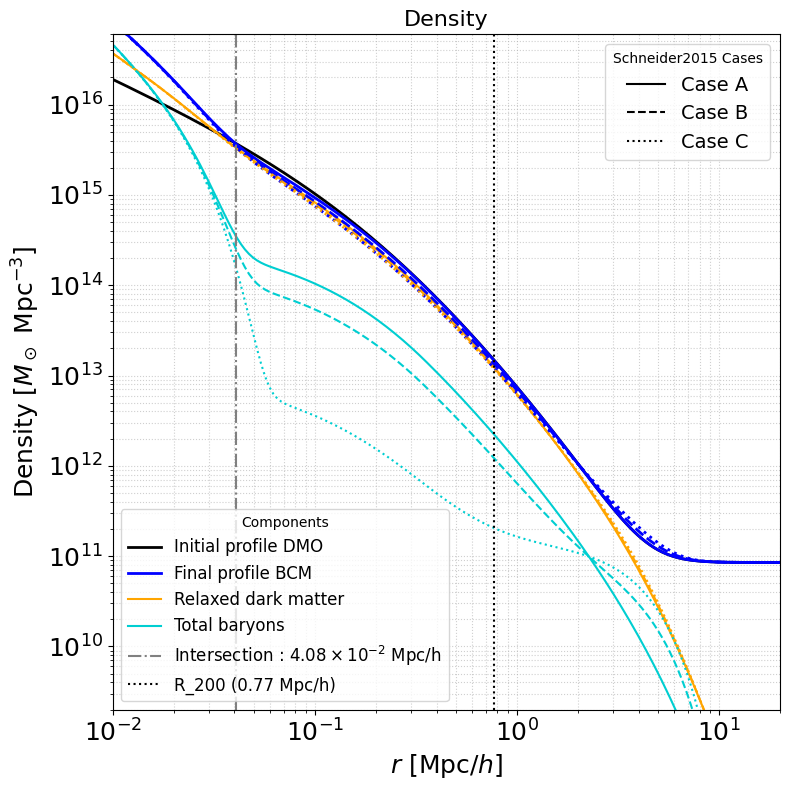

In [9]:
cases = ['A', 'B', 'C']
linestyles = {'A': '-', 'B': '--', 'C': ':'}

colors = {
    'dmo': 'black',
    'bcm': 'blue',
    'rdm': 'orange',
    'bound_gas': 'green',
    'central_gal': 'purple',
    'ejected_gas': 'red',
    'total_baryons': 'darkturquoise'
}

plt.figure(figsize=(fig,fig))

for i, case in enumerate(cases):
    config.SCHNEIDER2015_CASE = case

    if case == 'A':
        constantes.F_BOUNDED_GAS = 0.151
    elif case == 'B':
        constantes.F_BOUNDED_GAS = 0.078
    elif case == 'C':
        constantes.F_BOUNDED_GAS = 0.005
        
    constantes.F_EJECTED_GAS = 1.0 - constantes.F_RDM - constantes.F_BOUNDED_GAS - constantes.F_CENTRAL_GALAXY
    
    rho_bcm, rho_rdm, rho_baryons, initial_components, m_baryon_f_array, r_f, *extra_returns = contraction.contract_Schneider2015()
    
    ls = linestyles[case]

   
    if i == 0:
        plt.loglog(config.R, initial_components["rho_i_dm"] + constantes.RHO_BG, color=colors['dmo'], linewidth=2, linestyle='-')
        
    plt.loglog(config.R, rho_bcm + constantes.RHO_BG, color=colors['bcm'], linewidth=2, linestyle=ls)
    plt.loglog(config.R, constantes.F_RDM * rho_rdm, color=colors['rdm'], linestyle=ls)
    plt.loglog(config.R, rho_baryons, color=colors['total_baryons'], linestyle=ls)


plt.axvline(x=4.08e-2, c='grey', ls='-.')
plt.axvline(constantes.R_200, color='black', linestyle=':')

plt.xlabel(r'$r \ [\mathrm{Mpc}/h]$', fontsize=18)
plt.ylabel(r'Density [$M_\odot \ \mathrm{Mpc}^{-3}$]', fontsize=18)

plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)

plt.grid(True, which='both', ls=':', alpha=0.6)

component_lines = [
    Line2D([0], [0], color=colors['dmo'], lw=2, label='Initial profile DMO'),
    Line2D([0], [0], color=colors['bcm'], lw=2, label='Final profile BCM'),
    Line2D([0], [0], color=colors['rdm'], lw=1.5, label='Relaxed dark matter'),
    Line2D([0], [0], color=colors['total_baryons'], lw=1.5, label='Total baryons'),
    Line2D([0], [0], color='grey', lw=1.5, linestyle='-.', label=r'Intersection : $4.08\times 10^{-2}$ Mpc/h'),
    Line2D([0], [0], color='black', lw=1.5, linestyle=':', label=f'R_200 ({constantes.R_200} Mpc/h)')
]

legend_components = plt.legend(handles=component_lines, loc='lower left', fontsize=12, title="Components")

case_lines = [
    Line2D([0], [0], color='black', lw=1.5, linestyle='-', label='Case A'),
    Line2D([0], [0], color='black', lw=1.5, linestyle='--', label='Case B'),
    Line2D([0], [0], color='black', lw=1.5, linestyle=':', label='Case C')
]

legend_cases = plt.legend(handles=case_lines, loc='upper right', fontsize=14, title="Schneider2015 Cases")
plt.gca().add_artist(legend_components)
plt.title('Density', fontsize=16)
plt.tight_layout()
plt.show()

Relaxed dark matter stacked

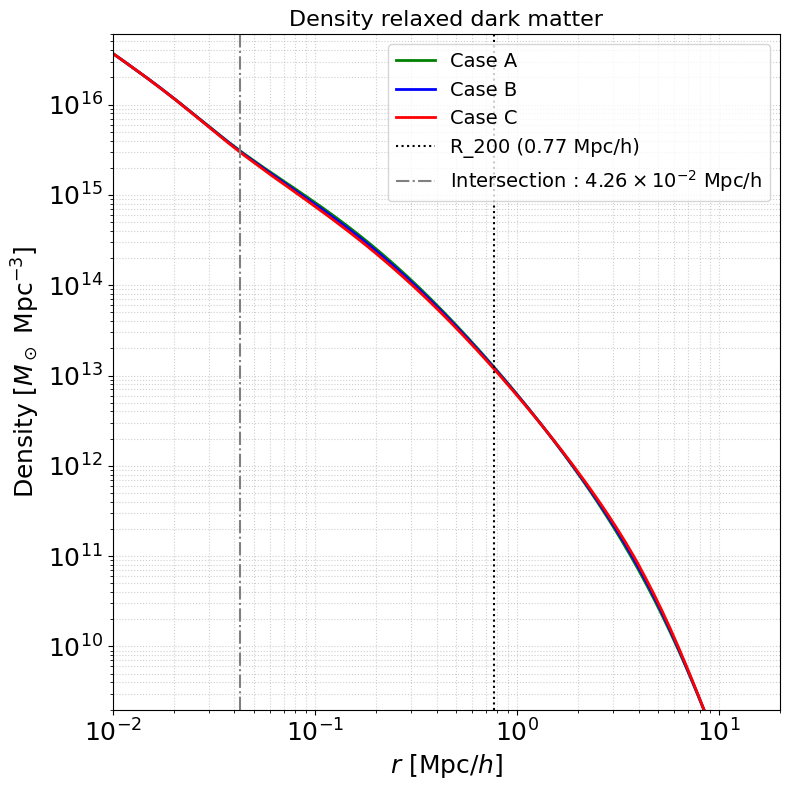

In [10]:
cases = ['A', 'B', 'C']
colors = {'A': 'green', 'B': 'blue', 'C': 'red'}

plt.figure(figsize=(fig,fig))

for case in cases:
    config.SCHNEIDER2015_CASE = case

    if case == 'A':
        constantes.F_BOUNDED_GAS = 0.151
    elif case == 'B':
        constantes.F_BOUNDED_GAS = 0.078
    elif case == 'C':
        constantes.F_BOUNDED_GAS = 0.005
        
    constantes.F_EJECTED_GAS = 1.0 - constantes.F_RDM - constantes.F_BOUNDED_GAS - constantes.F_CENTRAL_GALAXY
    
    rho_bcm, rho_rdm, rho_baryons, initial_components, m_baryon_f_array, r_f, *extra_returns = contraction.contract_Schneider2015()
    
    plt.loglog(config.R, constantes.F_RDM * rho_rdm, color=colors[case], linewidth=2, label=f'Case {case}')
plt.axvline(constantes.R_200, color='black', linestyle=':', label=f'R_200 ({constantes.R_200} Mpc/h)')
plt.axvline(x = 4.26e-2, label=r'Intersection : $4.26\times 10^{-2}$ Mpc/h', c='grey', ls='-.')
plt.xlabel(r'$r \ [\mathrm{Mpc}/h]$', fontsize=18)
plt.ylabel(r'Density [$M_\odot \ \mathrm{Mpc}^{-3}$]', fontsize=18)
plt.title('Density relaxed dark matter', fontsize=16)

plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)

plt.grid(True, which='both', ls=':', alpha=0.6)
plt.legend(fontsize=14, loc='upper right')

plt.tight_layout()
plt.show()

Baryonic Contraction Model stacked

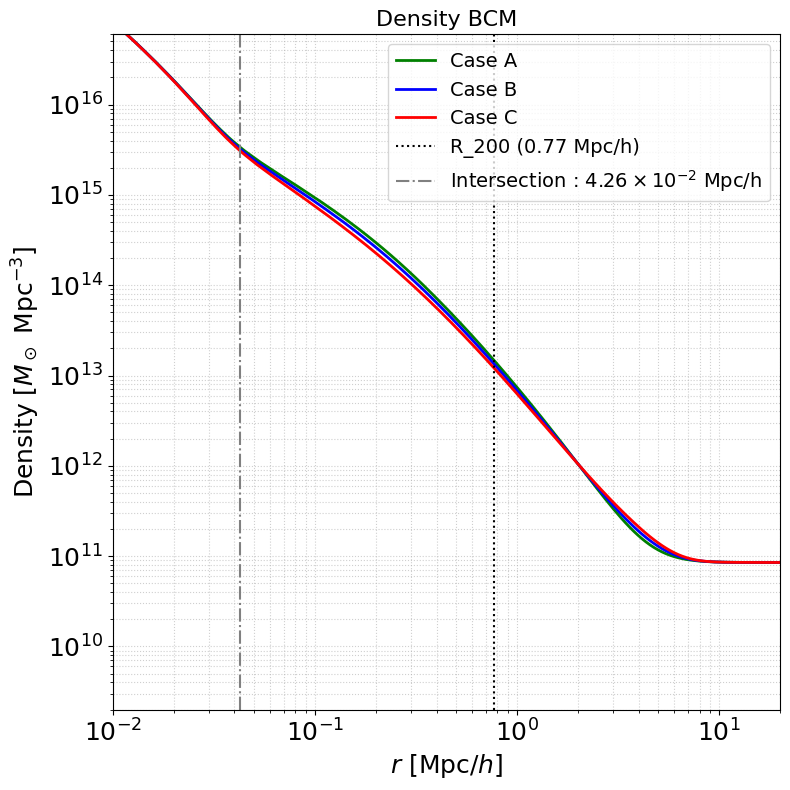

In [11]:
cases = ['A', 'B', 'C']
colors = {'A': 'green', 'B': 'blue', 'C': 'red'}

plt.figure(figsize=(fig,fig))

for case in cases:
    config.SCHNEIDER2015_CASE = case

    if case == 'A':
        constantes.F_BOUNDED_GAS = 0.151
    elif case == 'B':
        constantes.F_BOUNDED_GAS = 0.078
    elif case == 'C':
        constantes.F_BOUNDED_GAS = 0.005
        
    constantes.F_EJECTED_GAS = 1.0 - constantes.F_RDM - constantes.F_BOUNDED_GAS - constantes.F_CENTRAL_GALAXY
    
    rho_bcm, rho_rdm, rho_baryons, initial_components, m_baryon_f_array, r_f, *extra_returns = contraction.contract_Schneider2015()
    

    plt.loglog(config.R, rho_bcm + constantes.RHO_BG, color=colors[case], linewidth=2,label=f'Case {case}')
plt.axvline(constantes.R_200, color='black', linestyle=':', label=f'R_200 ({constantes.R_200} Mpc/h)')
plt.axvline(x = 4.26e-2, label=r'Intersection : $4.26\times 10^{-2}$ Mpc/h', c='grey', ls='-.')
plt.xlabel(r'$r \ [\mathrm{Mpc}/h]$', fontsize=18)
plt.ylabel(r'Density [$M_\odot \ \mathrm{Mpc}^{-3}$]', fontsize=18)
plt.title('Density BCM', fontsize=16)

plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)

plt.grid(True, which='both', ls=':', alpha=0.6)
plt.legend(fontsize=14, loc='upper right')

plt.tight_layout()
plt.show()

Ratio of final radius over initial radius

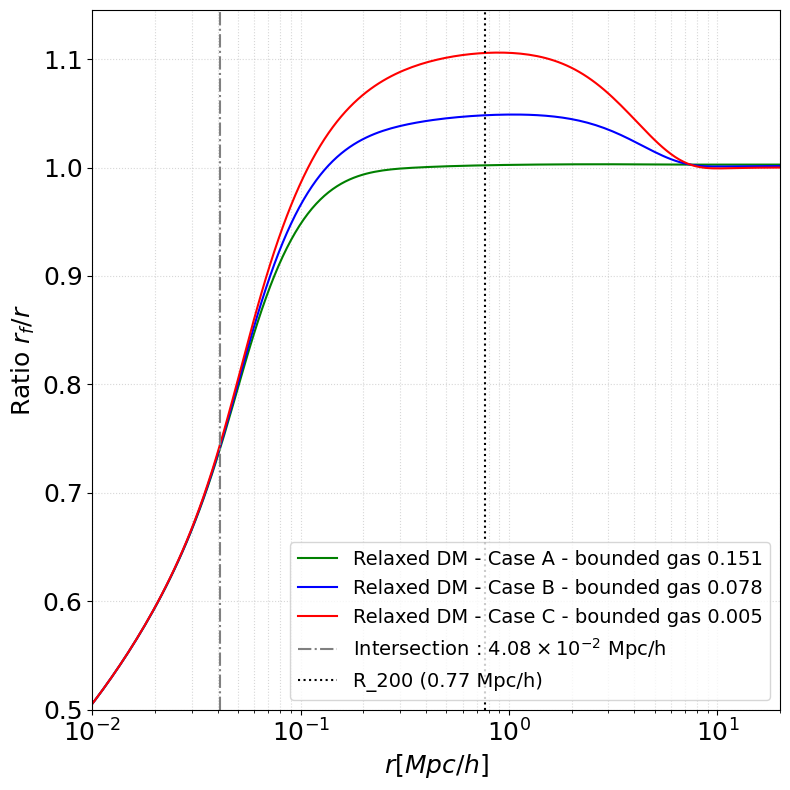

In [12]:
cases = ['A', 'B', 'C']
colors = ['green', 'blue', 'red']

plt.figure(figsize=(fig,fig))



for case, color in zip(cases, colors):
    config.SCHNEIDER2015_CASE = case

    if case == 'A':
        constantes.F_BOUNDED_GAS = 0.151
    elif case == 'B':
        constantes.F_BOUNDED_GAS = 0.078
    elif case == 'C':
        constantes.F_BOUNDED_GAS = 0.005
        
    constantes.F_EJECTED_GAS = 1.0 - constantes.F_RDM - constantes.F_BOUNDED_GAS - constantes.F_CENTRAL_GALAXY
    _, _, _, _, _, r_f = contraction.contract_Schneider2015()

    contraction_ratio = r_f / config.R 
    
    plt.semilogx(config.R, contraction_ratio, label=f"Relaxed DM - Case {case}"
                  f" - bounded gas {constantes.F_BOUNDED_GAS}", color=color)
                
plt.axvline(x = 4.08e-2, label=r'Intersection : $4.08\times 10^{-2}$ Mpc/h', c='grey', ls='-.')
plt.axvline(constantes.R_200, color='black', linestyle=':', label=f'R_200 ({constantes.R_200} Mpc/h)')
plt.xlabel(r'$r [Mpc/h]$', fontsize=18)
plt.ylabel(r'Ratio $r_f / r$', fontsize=18)
#plt.title('Contraction ratio', fontsize=13)
plt.xlim(x_min, x_max)
plt.ylim(0.5)
plt.grid(True, which="both", ls=":", alpha=0.5)
plt.legend(fontsize=14, loc="lower right")
plt.tight_layout()

plt.show()

Ratio of final mass of baryons over initial mass of dark matter

/var/folders/xc/6b_9m92x75116mj19j92v7br0000gn/T/ipykernel_8156/410657212.py:25: RuntimeWarning: invalid value encountered in divide
  mass_ratio = m_baryon_f_array / initial_components['M_i_dm']


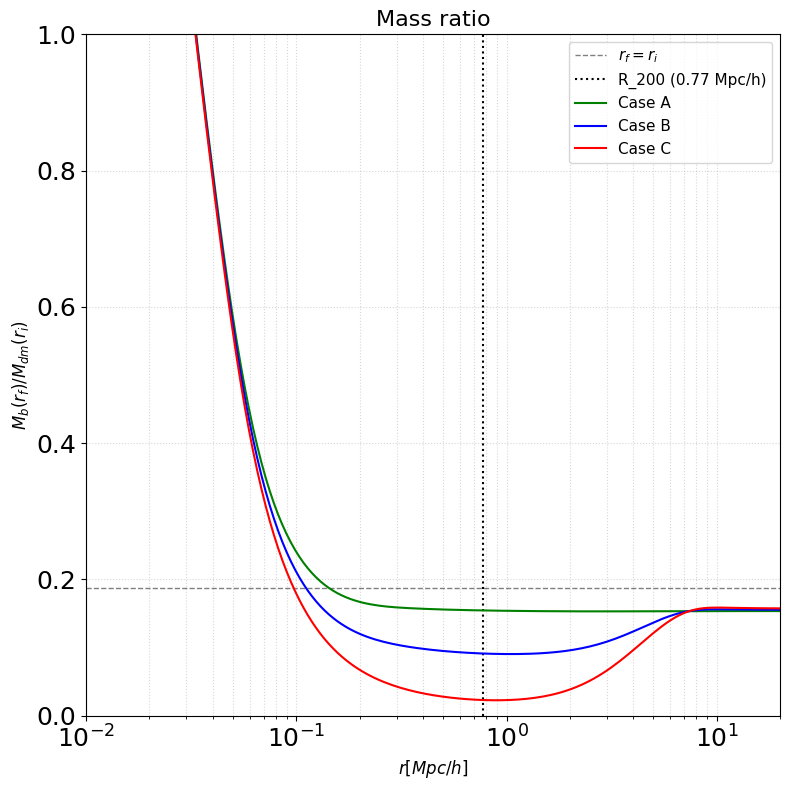

In [13]:
cases = ['A', 'B', 'C']
colors = ['green', 'blue', 'red']

x = 1 / constantes.F_RDM
lim =x -1 

plt.figure(figsize=(fig,fig))
plt.axhline(lim, color="black", lw=1, ls="--", alpha=0.5, label=r"$r_f = r_i$")
plt.axvline(constantes.R_200, color='black', linestyle=':', label=f'R_200 ({constantes.R_200} Mpc/h)')

for case, color in zip(cases, colors):
    config.SCHNEIDER2015_CASE = case

    if case == 'A':
        constantes.F_BOUNDED_GAS = 0.151
    elif case == 'B':
        constantes.F_BOUNDED_GAS = 0.078
    elif case == 'C':
        constantes.F_BOUNDED_GAS = 0.005
        
    constantes.F_EJECTED_GAS = 1.0 - constantes.F_RDM - constantes.F_BOUNDED_GAS - constantes.F_CENTRAL_GALAXY
    
    _, _, _, _, m_baryon_f_array, _ = contraction.contract_Schneider2015()

    mass_ratio = m_baryon_f_array / initial_components['M_i_dm']
    plt.semilogx(config.R, mass_ratio, label=f"Case {case}", color=color)

plt.xlabel(r'$r [Mpc/h]$', fontsize=12)
plt.ylabel(r'$M_b(r_f) / M_{dm}(r_i)$', fontsize=12)
plt.title('Mass ratio', fontsize=16)
plt.xlim(x_min, x_max)
plt.ylim(0, 1)
plt.grid(True, which="both", ls=":", alpha=0.5)
plt.legend(fontsize=11, loc="upper right")
plt.tight_layout()

plt.show()

Stacking of mass and radius

/var/folders/xc/6b_9m92x75116mj19j92v7br0000gn/T/ipykernel_8156/188945768.py:23: RuntimeWarning: invalid value encountered in divide
  mass_ratio = m_baryon_f_array / initial_components['M_i_dm']


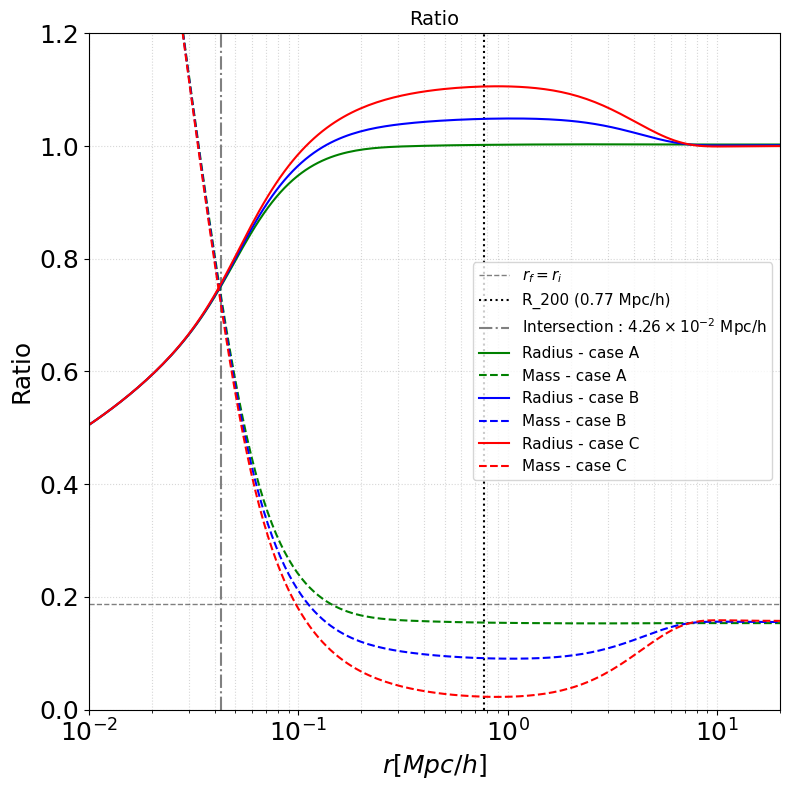

In [14]:
cases = ['A', 'B', 'C']
colors = ['green', 'blue', 'red']

plt.figure(figsize=(fig,fig))
plt.axhline(lim, color="black", lw=1, ls="--", alpha=0.5, label=r"$r_f = r_i$")
plt.axvline(constantes.R_200, color='black', linestyle=':', label=f'R_200 ({constantes.R_200} Mpc/h)')
plt.axvline(x = 4.26e-2, label=r'Intersection : $4.26\times 10^{-2}$ Mpc/h', c='grey', ls='-.')

for case, color in zip(cases, colors):
    config.SCHNEIDER2015_CASE = case

    if case == 'A':
        constantes.F_BOUNDED_GAS = 0.151
    elif case == 'B':
        constantes.F_BOUNDED_GAS = 0.078
    elif case == 'C':
        constantes.F_BOUNDED_GAS = 0.005
        
    constantes.F_EJECTED_GAS = 1.0 - constantes.F_RDM - constantes.F_BOUNDED_GAS - constantes.F_CENTRAL_GALAXY
    _, _, _, _, m_baryon_f_array, r_f = contraction.contract_Schneider2015()

    contraction_ratio = r_f / config.R 
    mass_ratio = m_baryon_f_array / initial_components['M_i_dm']

    plt.semilogx(config.R, contraction_ratio, label=f"Radius - case {case}", color=color)
    plt.semilogx(config.R, mass_ratio, label=f"Mass - case {case}", color=color, ls ='--')

plt.xlabel(r'$r [Mpc/h]$', fontsize=18)
plt.ylabel(r'Ratio', fontsize=18)
plt.title('Ratio', fontsize=14)
plt.xlim(x_min, x_max)
plt.ylim(0,1.2)
plt.grid(True, which="both", ls=":", alpha=0.5)
plt.legend(fontsize=11, loc="center right")
plt.tight_layout()

plt.show()

2 halo term

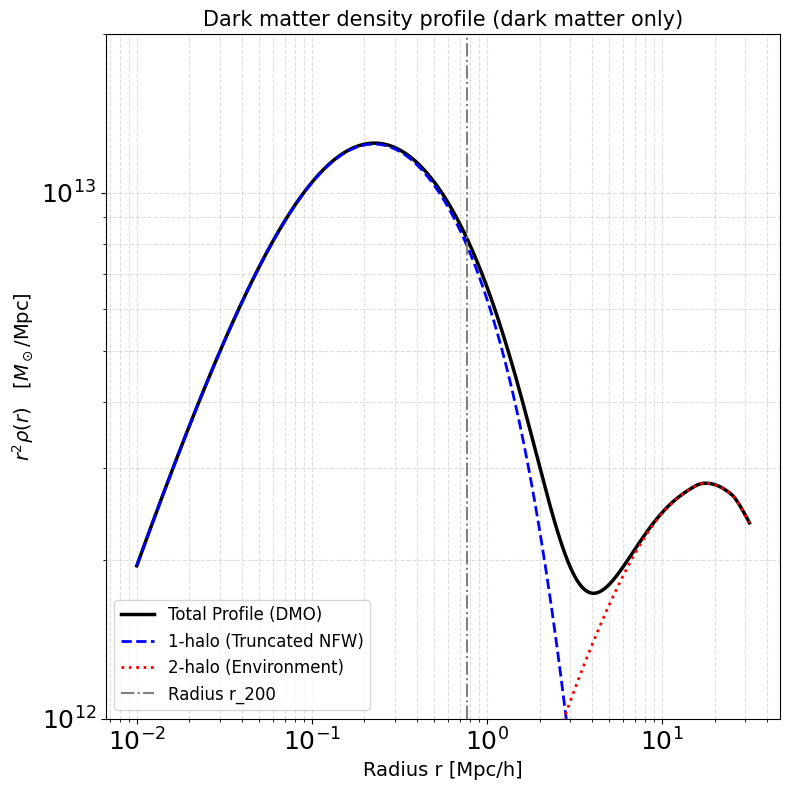

In [15]:
cosmo  = cosmology.setCosmology('WMAP7')

D_z = cosmo.growthFactor(constantes.Z)

# Generation of the linear power spectrum (k and P_lin)
k_array = np.logspace(-4, 3, 2000)
P_lin_array = cosmo.matterPowerSpectrum(k_array, z=constantes.Z)
 


# Radius grid from 0.01 Mpc/h to ~31 Mpc/h
r_values = np.logspace(-2, 1.5, 500)

rho_tot_list = []
rho_nfw_list = []
rho_2h_list = []

for r_current in r_values:
    tot, nfw, h2 = profiles.calculate_rho_dmo(
        r=r_current,
        M_200=config.HALO_MASS ,
        c=config.CONCENTRATION,
        D_z=D_z,
        Omega_m=constantes.OMEGA_M,
        rho_crit=constantes.RHO_C ,
        k_arr=k_array,
        P_lin_arr=P_lin_array
    )
    rho_tot_list.append(tot)
    rho_nfw_list.append(nfw)
    rho_2h_list.append(h2)

rho_tot_array = np.array(rho_tot_list)
rho_nfw_array = np.array(rho_nfw_list)
rho_2h_array = np.array(rho_2h_list)

plt.figure(figsize=(fig,fig))
plt.loglog(r_values, r_values**2 * rho_tot_array, 'k-', linewidth=2.5, label='Total Profile (DMO)')
plt.loglog(r_values, r_values**2 * rho_nfw_array, 'b--', linewidth=2, label='1-halo (Truncated NFW)')
plt.loglog(r_values, r_values**2 * rho_2h_array, 'r:', linewidth=2, label='2-halo (Environment)')
plt.axvline(x=constantes.R_200, color='gray', linestyle='-.', label=f'Radius r_200')
plt.ylim(1e12, 2e13)
plt.xlabel('Radius r [Mpc/h]', fontsize=14)
plt.ylabel(r'$r^2 \rho(r) \quad [M_\odot / \mathrm{Mpc}]$', fontsize=14)
plt.title('Dark matter density profile (dark matter only)', fontsize=15)
plt.grid(True, which="both", ls="--", alpha=0.4)
plt.legend(fontsize=12, loc='lower left')
plt.tight_layout()
plt.show()